# Measure the cost of screening optimizer proposals

**Question:** Does the learned screen reduce exact circuit evaluations while preserving the engine-verified operating point?

Level: 4. Prerequisites: levels 1–3 in this topic. Reading time: 32 minutes.

## Objectives

This investigation tests a specific engineering claim: a learned score may help a constrained search spend fewer calls on its exact process simulator. You will examine the paired, committed records for every screened operating variant, quantify the evaluation cost, and independently re-run selected reported optima through the circuit engine. A negative result is useful here because the screen is an optimization component whose cost must be measured, not assumed.

## Setup

Pinned environment; install once in the repository environment with this command, not in the notebook:

```bash
pip install numpy==2.2.6 pandas==2.2.3 matplotlib==3.11.2
```

The notebook only reports installed versions and never writes to the source records.

## Data

The primary data are OreFlow-authored, versioned scenario records in `data/derived/cases/<case_id>.json`, released under the repository's MIT licence. The records contain the screened search, its same-start unscreened counterpart, final decisions and engine-evaluation counts. The twelve cases are constructed scenarios, not operating-plant observations. The optimizer's controls and case bounds are in `data/derived/contract/operating_contract.json`; the method and limitations are documented in `docs/methodologies/12_optimization.md`. The source repository is https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

For each variant, let N_s be the number of distinct exact-engine evaluations made by the screen-assisted search and N_0 the count from the matched search without screening. The paired difference is d=N_s-N_0; the relative cost is 100d/N_0. Negative d would mean fewer simulator calls. A zero difference means no change. Positive d is additional simulator work. We do not compare unrelated seeds, starts, constraints or objectives: both counts belong to the same committed optimization record and use its same operating case and weight. This pairing controls the scenario and search configuration, but it does not make the authored scenarios a sample of real plants.

The screen is allowed to rank proposals, but the exact process engine evaluates a candidate before it can replace an incumbent. Therefore the key integrity check is not whether the surrogate predicts a good score; it is whether each stored optimum is a valid engine result. The code below reconstructs each saved decision vector from the catalogued base point, invokes OreFlow's production `simulate` method and compares the recovered payable-metal rate with the record. It also checks the maximum balance residual returned by the engine. Small disagreement would indicate a stale record, a changed method or a reconstruction error, and would invalidate the comparison until resolved.

Two views answer different questions. The paired scatter shows whether one procedure consistently uses fewer evaluations; the identity line marks equal cost. The per-case plot shows how an aggregate can conceal variation between ore scenarios. The number of variants is not the number of independent mines: several variants share a case and differ by one controlled input. We report counts and exact paired differences instead of a confidence interval that would imply a population sampling design the data do not have.

## Comparison

The search itself is generalized pattern search with a progressive barrier for grade, power and water constraints. The learned component is only a proposal-ordering screen. The reference procedure is the same constrained search with the screen disabled, not a different optimizer chosen to make the comparison easier. Both procedures retain the exact circuit engine as evaluator. This distinction matters: a fast prediction is not a saving if it leads to extra search steps or changes the selected physical operating point.

The proposed benefit is reduced calls to the expensive process model. We evaluate that benefit directly with the committed paired counts, then check the selected operating points against `simulate`. We do not infer a speed improvement from model inference latency, from the fact that a screen rejected candidates, or from a small surrogate error at a few points. Those quantities do not measure total work or establish that the screen is useful to an operator.

Record the pinned library versions before importing the analysis and process methods.

In [1]:
# Record the exact analysis-library versions used by this lesson.
import importlib.metadata

for package in ("numpy", "pandas", "matplotlib"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
pandas 2.2.3
matplotlib 3.11.2


Import the analysis tools and bind to OreFlow's production circuit method.

In [2]:
# Import the analysis tools and the production circuit engine.
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case_by_id = {case.id: case for case in CASES}
print("scenario count:", len(case_by_id))
print("engine method:", simulate.__module__ + "." + simulate.__name__)


scenario count: 12
engine method: pipeline.engine.circuit.simulate


Read the paired scenario records and calculate one row per screened variant; the raw files remain unchanged.

In [3]:
# Load the committed paired records without changing them.
records = []
for path in sorted((repo / "data/derived/cases").glob("*.json")):
    artifact = json.loads(path.read_text(encoding="utf-8"))
    for variant in artifact["variants"]:
        result = variant["methods"]["optimization"]
        if not result.get("screened") or "without_screen" not in result:
            continue
        plain = result["without_screen"]
        optimum = result.get("optimum") or {}
        records.append(
            {
                "case_id": artifact["case_id"],
                "variant_id": variant["id"],
                "screened_evaluations": result["evaluations"],
                "plain_evaluations": plain["evaluations"],
                "metal_screened_tph": optimum.get("recovered_tph", np.nan),
                "metal_plain_tph": plain.get("recovered_tph", np.nan),
            }
        )
paired = pd.DataFrame(records)
paired["difference"] = paired.screened_evaluations - paired.plain_evaluations
paired["relative_cost_pct"] = 100 * paired.difference / paired.plain_evaluations
print("paired variants:", len(paired))
display(paired.head())


paired variants: 72


,case_id,variant_id,screened_evaluations,plain_evaluations,metal_screened_tph,metal_plain_tph,difference,relative_cost_pct
0,copper_molybdenum,nominal,347,266,3.826023,3.826023,81,30.451128
1,copper_molybdenum,harder_ore,470,368,3.635680,3.635680,102,27.717391
2,copper_molybdenum,coarser_grind,349,267,3.826023,3.826023,82,30.711610
3,copper_molybdenum,higher_throughput,339,269,4.488142,4.488142,70,26.022305
4,copper_molybdenum,more_collector,365,279,3.826023,3.826023,86,30.824373


Re-evaluate a saved optimum with the engine. The small residual checks reproducibility; it is not plant validation.

Reconstruct the reported copper porphyry soft optimum from its decisions and check the engine output against the stored record.

In [4]:
# Re-run this saved decision vector through the production circuit engine.
case_id = "copper_porphyry_soft"
artifact = json.loads((repo / f"data/derived/cases/{case_id}.json").read_text(encoding="utf-8"))
variant = next(v for v in artifact["variants"] if v["methods"]["optimization"].get("optimum"))
case = case_by_id[case_id]
optimum = variant["methods"]["optimization"]["optimum"]
operating_point = case.nominal.with_values(**optimum["decisions"])
trace = simulate(case.ore, case.plant, operating_point)
recorded = optimum["recovered_tph"]
recomputed = trace.metrics["recovered_primary_tph"]
print(
    case_id,
    variant["id"],
    "recorded:",
    round(recorded, 6),
    "engine:",
    round(recomputed, 6),
    "balance:",
    trace.metrics["balance_max_relative_error"],
)


copper_porphyry_soft nominal recorded: 5.195311 engine: 5.195311 balance: 7.756758198714425e-13


Reconstruct the reported copper oxide optimum from its decisions and check the engine output against the stored record.

In [5]:
# Re-run this saved decision vector through the production circuit engine.
case_id = "copper_oxide"
artifact = json.loads((repo / f"data/derived/cases/{case_id}.json").read_text(encoding="utf-8"))
variant = next(v for v in artifact["variants"] if v["methods"]["optimization"].get("optimum"))
case = case_by_id[case_id]
optimum = variant["methods"]["optimization"]["optimum"]
operating_point = case.nominal.with_values(**optimum["decisions"])
trace = simulate(case.ore, case.plant, operating_point)
recorded = optimum["recovered_tph"]
recomputed = trace.metrics["recovered_primary_tph"]
print(
    case_id,
    variant["id"],
    "recorded:",
    round(recorded, 6),
    "engine:",
    round(recomputed, 6),
    "balance:",
    trace.metrics["balance_max_relative_error"],
)


copper_oxide nominal recorded: 5.028551 engine: 5.028551 balance: 2.6829113643355508e-14


Reconstruct the reported gold free milling optimum from its decisions and check the engine output against the stored record.

In [6]:
# Re-run this saved decision vector through the production circuit engine.
case_id = "gold_free_milling"
artifact = json.loads((repo / f"data/derived/cases/{case_id}.json").read_text(encoding="utf-8"))
variant = next(v for v in artifact["variants"] if v["methods"]["optimization"].get("optimum"))
case = case_by_id[case_id]
optimum = variant["methods"]["optimization"]["optimum"]
operating_point = case.nominal.with_values(**optimum["decisions"])
trace = simulate(case.ore, case.plant, operating_point)
recorded = optimum["recovered_tph"]
recomputed = trace.metrics["recovered_primary_tph"]
print(
    case_id,
    variant["id"],
    "recorded:",
    round(recorded, 6),
    "engine:",
    round(recomputed, 6),
    "balance:",
    trace.metrics["balance_max_relative_error"],
)


gold_free_milling nominal recorded: 0.000878 engine: 0.000878 balance: 5.647903797067463e-14


Reconstruct the reported nickel sulphide optimum from its decisions and check the engine output against the stored record.

In [7]:
# Re-run this saved decision vector through the production circuit engine.
case_id = "nickel_sulphide"
artifact = json.loads((repo / f"data/derived/cases/{case_id}.json").read_text(encoding="utf-8"))
variant = next(v for v in artifact["variants"] if v["methods"]["optimization"].get("optimum"))
case = case_by_id[case_id]
optimum = variant["methods"]["optimization"]["optimum"]
operating_point = case.nominal.with_values(**optimum["decisions"])
trace = simulate(case.ore, case.plant, operating_point)
recorded = optimum["recovered_tph"]
recomputed = trace.metrics["recovered_primary_tph"]
print(
    case_id,
    variant["id"],
    "recorded:",
    round(recorded, 6),
    "engine:",
    round(recomputed, 6),
    "balance:",
    trace.metrics["balance_max_relative_error"],
)


nickel_sulphide nominal recorded: 4.03034 engine: 4.03034 balance: 1.2667902902374115e-12


Reconstruct the reported zinc sulfide optimum from its decisions and check the engine output against the stored record.

In [8]:
# Re-run this saved decision vector through the production circuit engine.
case_id = "zinc_sulfide"
artifact = json.loads((repo / f"data/derived/cases/{case_id}.json").read_text(encoding="utf-8"))
variant = next(v for v in artifact["variants"] if v["methods"]["optimization"].get("optimum"))
case = case_by_id[case_id]
optimum = variant["methods"]["optimization"]["optimum"]
operating_point = case.nominal.with_values(**optimum["decisions"])
trace = simulate(case.ore, case.plant, operating_point)
recorded = optimum["recovered_tph"]
recomputed = trace.metrics["recovered_primary_tph"]
print(
    case_id,
    variant["id"],
    "recorded:",
    round(recorded, 6),
    "engine:",
    round(recomputed, 6),
    "balance:",
    trace.metrics["balance_max_relative_error"],
)


zinc_sulfide nominal recorded: 35.629143 engine: 35.629143 balance: 9.528764163574008e-14


## Evidence

The fixed release record includes 72 screened target-mode variants across twelve authored cases. Its aggregate counts are 26,367 engine evaluations with screening and 22,487 without it. Screening therefore adds 3,880 evaluations, a 17.3% increase relative to the unscreened count. It saves evaluations in zero variants, costs more in 68, and leaves four unchanged. The comparison is paired within each variant; the figures retain that pairing rather than hiding it in one mean.

The same records report that 65 variants finish at the same decisions. For the differing terminal decisions, recovered metal differs by at most 0.02% in the documented suite. That outcome does not rescue the evaluation-cost hypothesis: matching an answer while spending more exact-engine evaluations is not a compute saving. Re-running selected optima is a separate integrity check, not a second performance comparison. The result is bounded to the committed synthetic scenarios and the recorded algorithm settings.

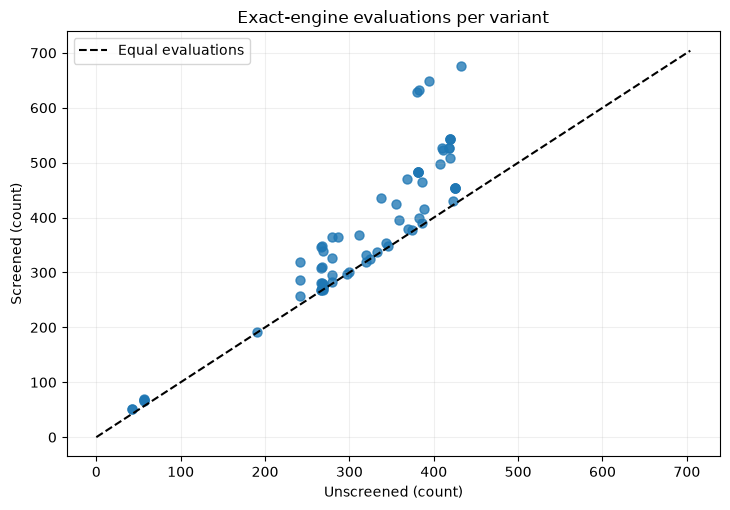

In [9]:
# Plot the paired exact-engine counts for every screened variant.
fig, ax = plt.subplots(figsize=(7.4, 5.2))
ax.scatter(paired.plain_evaluations, paired.screened_evaluations, alpha=0.78, s=42)
limit = max(paired.plain_evaluations.max(), paired.screened_evaluations.max()) * 1.04
ax.plot([0, limit], [0, limit], color="black", linestyle="--", label="Equal evaluations")
ax.set(xlabel="Unscreened (count)", ylabel="Screened (count)")
ax.set_title("Exact-engine evaluations per variant")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()


Points above the dashed identity line require more exact circuit evaluations with screening. A point below it is a saving for that one paired variant. Read the distribution together with the total: equal weighting of variants is transparent here, but the cases are authored and not sampled from operating plants. The plot describes this committed algorithm run only.

Aggregate the paired changes by ore scenario to expose variation hidden by the total.

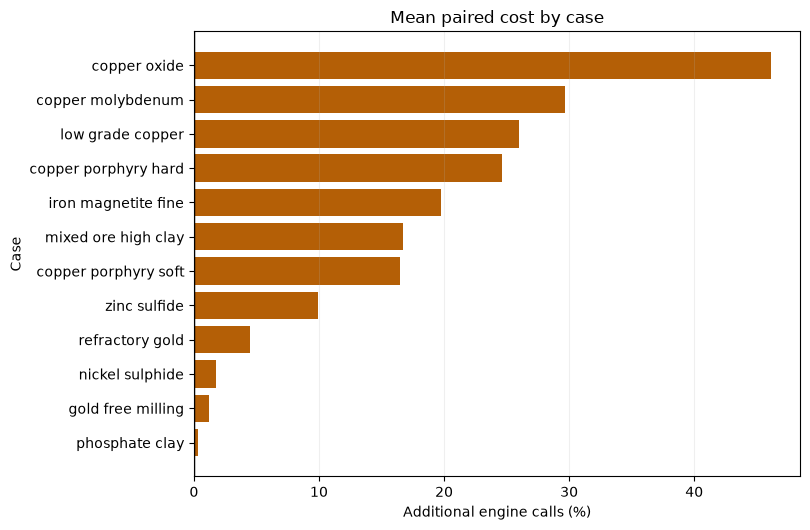

In [10]:
# Summarize the paired evaluation difference within each authored case.
by_case = paired.groupby("case_id", as_index=False).agg(
    mean_relative_cost_pct=("relative_cost_pct", "mean"), variants=("variant_id", "count")
)
by_case = by_case.sort_values("mean_relative_cost_pct")
fig, ax = plt.subplots(figsize=(8.2, 5.4))
colors = np.where(by_case.mean_relative_cost_pct > 0, "#b45f06", "#2878a0")
ax.barh(by_case.case_id.str.replace("_", " "), by_case.mean_relative_cost_pct, color=colors)
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Additional engine calls (%)", ylabel="Case")
ax.set_title("Mean paired cost by case")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()


A positive bar means that the screen increased the mean exact-engine count across the case's controlled variants; a negative bar would mean fewer calls. Bars are descriptive summaries, not independent estimates. Variants within one case share ore, plant definition and most operating settings. This view therefore helps find case-specific cost patterns without making a claim about frequencies in industry.

Compute the paired totals and count how many variants save or add engine calls.

In [11]:
# Sum the paired counts and report the direction of every variant.
screen_total = int(paired.screened_evaluations.sum())
plain_total = int(paired.plain_evaluations.sum())
delta_total = screen_total - plain_total
relative_total = 100 * delta_total / plain_total
print("screened total:", screen_total)
print("unscreened total:", plain_total)
print("additional evaluations:", delta_total)
print("relative increase (%):", round(relative_total, 1))
print("variants with fewer evaluations:", int((paired.difference < 0).sum()))
print("variants with more evaluations:", int((paired.difference > 0).sum()))
print("unchanged variants:", int((paired.difference == 0).sum()))


screened total: 26367
unscreened total: 22487
additional evaluations: 3880
relative increase (%): 17.3
variants with fewer evaluations: 0
variants with more evaluations: 68
unchanged variants: 4


## Results

**Answer:** The screen does not reduce exact-engine work on this release's 72 paired variants: it uses 26,367 evaluations versus 22,487 without screening, a 17.3% increase. The paired plot shows the direction for each variant; the engine re-runs test whether stored optima remain reproducible. This refutes the proposed compute-saving hypothesis for this suite. It does not establish how the method would behave on measured plant data, under another training design, or with different search settings.

## Summary

The screen's intended role is limited to ordering proposals; the circuit engine remains responsible for every physical result. The measured record answers the cost question directly and gives a negative result: screening adds exact evaluations for this scenario suite. Keep that finding visible when discussing the optimizer. Any later screen revision needs a new matched experiment, the same engine-verification check and a fresh notebook run; it cannot inherit a speed claim from this result.

## References

- Torczon (1997), On the convergence of pattern search algorithms. https://doi.org/10.1137/S1052623493250780
- Audet and Dennis (2009), Mesh adaptive direct search algorithms for constrained optimization. https://doi.org/10.1137/070692662
- Booker et al. (1999), Managing the evaluation of engineering design problems with surrogate models. https://doi.org/10.1007/BF01197708
- OreFlow constrained optimization method and measured records: `docs/methodologies/12_optimization.md` and `data/derived/cases/`.